# Student Performance Exploratory Data Analysis

This report explores the 1,200-student dataset generated by `generate_data.py` (seed 55). It describes the data, identifies performance patterns and compares school types to inform learner-support targeting. The data are synthetic; findings describe this generated sample rather than establish effects in real schools.

## Structure

**Grain:** one row per student. `student_id` is an identifier; `county`, `school_type` and `gender` are categorical; `attendance_rate` is a proportion; `study_hours` is a numeric study-time measure; and `math`, `english` and `science` are subject scores. The checks below report dimensions, types, missing values, duplicate rows/IDs, category levels and valid value ranges.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

DATA_PATH = Path("student_performance.csv")
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

students = pd.read_csv(DATA_PATH)
print(f"Shape: {students.shape[0]:,} rows x {students.shape[1]} columns")
print("\nColumn types:")
print(students.dtypes)

quality_checks = pd.Series({
    "missing cells": int(students.isna().sum().sum()),
    "duplicate rows": int(students.duplicated().sum()),
    "duplicate student IDs": int(students["student_id"].duplicated().sum()),
    "attendance outside [0, 1]": int((~students["attendance_rate"].between(0, 1)).sum()),
    "subject scores outside [0, 100]": int((~students[["math", "english", "science"]].apply(
        lambda column: column.between(0, 100)).all(axis=1)).sum()),
})
print("\nData-quality checks (all should be zero):")
print(quality_checks)
print("\nCategorical levels:")
for column in ["county", "school_type", "gender"]:
    print(f"{column}: {sorted(students[column].unique())}")

Shape: 1,200 rows x 9 columns

Column types:
student_id           int64
county                 str
school_type            str
gender                 str
attendance_rate    float64
study_hours        float64
math               float64
english            float64
science            float64
dtype: object

Data-quality checks (all should be zero):
missing cells                      0
duplicate rows                     0
duplicate student IDs              0
attendance outside [0, 1]          0
subject scores outside [0, 100]    0
dtype: int64

Categorical levels:
county: ['Kisumu', 'Mombasa', 'Nairobi', 'Nakuru', 'Nyeri', 'Turkana']
school_type: ['Private', 'Public']
gender: ['F', 'M']


## Univariate

The numeric table includes centre (mean and median), spread (standard deviation, quartiles and range) and shape (skewness) for every numeric field. `student_id` is included to satisfy the numeric summary, but is an identifier rather than a measured quantity. Categorical tables show counts and shares. Study-hour outliers are flagged with the 1.5 x IQR rule.

In [2]:
students["average_score"] = students[["math", "english", "science"]].mean(axis=1)
numeric_columns = students.select_dtypes(include="number").columns
numeric_summary = students[numeric_columns].describe().T
numeric_summary["median"] = students[numeric_columns].median()
numeric_summary["skew"] = students[numeric_columns].skew()
display(numeric_summary.round(3))

categorical_columns = ["county", "school_type", "gender"]
for column in categorical_columns:
    counts = students[column].value_counts().rename("count")
    shares = students[column].value_counts(normalize=True).rename("share")
    print(f"\n{column} counts and shares:")
    display(pd.concat([counts, shares], axis=1).assign(share=lambda table: table["share"].map("{:.1%}".format)))

q1 = students["study_hours"].quantile(0.25)
q3 = students["study_hours"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
study_hour_outliers = students.loc[
    ~students["study_hours"].between(lower_fence, upper_fence), "study_hours"
]
print(f"\nStudy-hours IQR fences: {lower_fence:.2f} to {upper_fence:.2f}")
print(f"Study-hours outliers: {len(study_hour_outliers)} ({len(study_hour_outliers) / len(students):.1%}); "
      f"range {study_hour_outliers.min():.1f} to {study_hour_outliers.max():.1f} hours")

,count,mean,std,min,25%,50%,75%,max,median,skew
student_id,1200.0,600.500,346.554,1.000,300.750,600.500,900.250,1200.0,600.500,0.000
attendance_rate,1200.0,0.804,0.119,0.330,0.730,0.820,0.900,1.0,0.820,-0.858
study_hours,1200.0,5.078,3.028,0.200,2.900,4.500,6.700,23.3,4.500,1.174
math,1200.0,71.889,10.858,37.000,65.000,72.000,79.000,100.0,72.000,0.102
english,1200.0,74.521,10.487,47.000,67.000,74.000,81.000,100.0,74.000,0.160
science,1200.0,69.612,12.022,35.000,61.000,69.000,78.000,100.0,69.000,0.107
average_score,1200.0,72.008,9.106,48.333,65.667,71.667,77.667,100.0,71.667,0.262



county counts and shares:


,count,share
county,,
Mombasa,212,17.7%
Kisumu,208,17.3%
Nyeri,203,16.9%
Nakuru,202,16.8%
Turkana,191,15.9%
Nairobi,184,15.3%



school_type counts and shares:


,count,share
school_type,,
Public,866,72.2%
Private,334,27.8%



gender counts and shares:


,count,share
gender,,
F,612,51.0%
M,588,49.0%



Study-hours IQR fences: -2.80 to 12.40
Study-hours outliers: 29 (2.4%); range 12.5 to 23.3 hours


In [3]:
students["performance_band"] = pd.cut(
    students["average_score"],
    bins=[-np.inf, 60, 75, np.inf],
    labels=["At Risk", "Meeting", "Exceeding"],
    right=False,
)

band_summary = students["performance_band"].value_counts(sort=False).rename("count").to_frame()
band_summary["share"] = students["performance_band"].value_counts(normalize=True, sort=False)
band_summary["share"] = band_summary["share"].map("{:.1%}".format)
print("Performance bands (At Risk < 60; Meeting 60-<75; Exceeding >= 75):")
display(band_summary)
print(f"\nAverage score: {students['average_score'].mean():.2f}; median: {students['average_score'].median():.2f}")

Performance bands (At Risk < 60; Meeting 60-<75; Exceeding >= 75):


,count,share
performance_band,,
At Risk,99,8.2%
Meeting,672,56.0%
Exceeding,429,35.8%



Average score: 72.01; median: 71.67


### Chart: average-score distribution

`average_score_histogram.png` shows the distribution of the derived three-subject average.

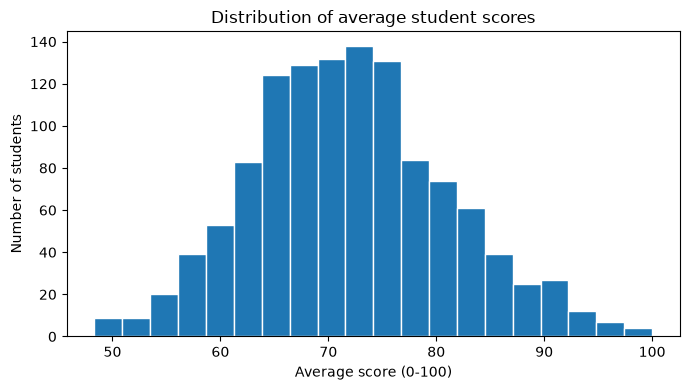

In [4]:
ax = students["average_score"].plot(kind="hist", bins=20, edgecolor="white", figsize=(7, 4),
                                    title="Distribution of average student scores")
ax.set_xlabel("Average score (0-100)")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "average_score_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

### Chart: performance-band counts

`performance_band_counts.png` compares the number of learners in each score band.

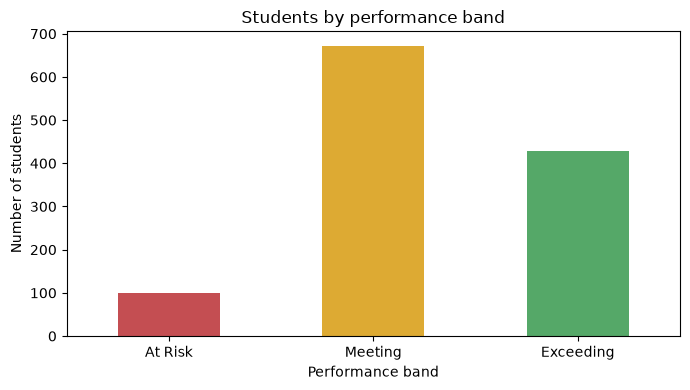

In [5]:
ax = students["performance_band"].value_counts(sort=False).plot(
    kind="bar", color=["#c44e52", "#ddaa33", "#55a868"], figsize=(7, 4),
    title="Students by performance band")
ax.set_xlabel("Performance band")
ax.set_ylabel("Number of students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "performance_band_counts.png", dpi=150, bbox_inches="tight")
plt.show()

## Bivariate

The correlation matrix covers all numeric variables, including the derived average. The three strongest correlations with `average_score` are the three component subject scores; because the average is calculated from those subjects, these are partly mathematical rather than independent evidence. Group means and the county-level At Risk share give the requested categorical comparisons.

In [6]:
correlation_matrix = students.select_dtypes(include="number").corr()
print("Correlation matrix:")
display(correlation_matrix.round(3))

average_correlations = correlation_matrix["average_score"].drop("average_score")
strongest_three = average_correlations.reindex(
    average_correlations.abs().sort_values(ascending=False).index
).head(3)
print("\nThree strongest correlations with average_score:")
display(strongest_three.rename("correlation").to_frame().round(3))

print("\nMean average score by gender:")
display(students.groupby("gender", observed=True)["average_score"].agg(["mean", "count"]).round(2))
print("\nMean average score by school type:")
display(students.groupby("school_type", observed=True)["average_score"].agg(["mean", "count"]).round(2))
print("\nMean average score by county:")
county_summary = students.groupby("county", observed=True)["average_score"].agg(["mean", "count"]).sort_values("mean", ascending=False)
display(county_summary.round(2))

county_risk_share = pd.crosstab(
    students["county"], students["performance_band"], normalize="index"
).reindex(columns=["At Risk", "Meeting", "Exceeding"])
county_risk_share["At Risk count"] = students.loc[
    students["performance_band"].eq("At Risk")
].groupby("county").size()
county_risk_share = county_risk_share.sort_values("At Risk", ascending=False)
print("\nCounty performance-band shares (sorted by At Risk share):")
display(county_risk_share.round(3))

Correlation matrix:


,student_id,attendance_rate,study_hours,math,english,science,average_score
student_id,1.000,-0.016,-0.016,0.027,0.002,-0.019,0.003
attendance_rate,-0.016,1.000,-0.029,0.300,0.327,0.260,0.359
study_hours,-0.016,-0.029,1.000,0.560,0.624,0.550,0.704
math,0.027,0.300,0.560,1.000,0.559,0.459,0.814
english,0.002,0.327,0.624,0.559,1.000,0.502,0.827
science,-0.019,0.260,0.550,0.459,0.502,1.000,0.815
average_score,0.003,0.359,0.704,0.814,0.827,0.815,1.000



Three strongest correlations with average_score:


,correlation
english,0.827
science,0.815
math,0.814



Mean average score by gender:


,mean,count
gender,,
F,72.10,612
M,71.91,588


... (2 outputs left out)


Mean average score by county:


,mean,count
county,,
Kisumu,73.07,208
Mombasa,72.17,212
Nairobi,71.96,184
Nyeri,71.94,203
Nakuru,71.84,202
Turkana,70.97,191



County performance-band shares (sorted by At Risk share):


performance_band,At Risk,Meeting,Exceeding,At Risk count
county,,,,
Nairobi,0.092,0.554,0.353,17
Mombasa,0.090,0.542,0.368,19
Nyeri,0.089,0.547,0.365,18
Kisumu,0.082,0.505,0.413,17
Turkana,0.079,0.597,0.325,15
Nakuru,0.064,0.619,0.317,13


### Chart: average-score box plot by school type

`average_score_by_school_type.png` compares score distributions, not just group means.

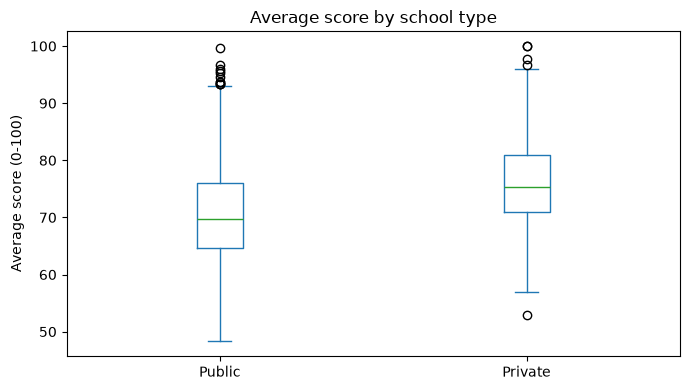

In [7]:
score_by_school = students.pivot(columns="school_type", values="average_score")
ax = score_by_school[["Public", "Private"]].plot(kind="box", figsize=(7, 4),
                                                  title="Average score by school type", showfliers=True)
ax.set_ylabel("Average score (0-100)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "average_score_by_school_type.png", dpi=150, bbox_inches="tight")
plt.show()

## Multivariate

These pivot tables compare Public and Private mean scores within attendance bands and study-hour quartiles. The `Private - Public` column is the within-stratum gap; counts are included because small strata can make subgroup means unstable.

In [8]:
students["attendance_band"] = pd.cut(
    students["attendance_rate"], bins=[0, 0.70, 0.85, 0.95, 1.01],
    labels=["<=70%", "71-85%", "86-95%", ">95%"], include_lowest=True,
)
students["study_hour_quartile"] = pd.qcut(
    students["study_hours"], q=4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"]
)

def school_type_pivot(group_column):
    means = students.pivot_table(
        index=group_column, columns="school_type", values="average_score", aggfunc="mean", observed=False
    )
    counts = students.pivot_table(
        index=group_column, columns="school_type", values="average_score", aggfunc="count", observed=False
    )
    means["Private - Public"] = means["Private"] - means["Public"]
    return means.round(2), counts

attendance_means, attendance_counts = school_type_pivot("attendance_band")
print("Mean average score by attendance band and school type:")
display(attendance_means)
print("Cell counts:")
display(attendance_counts)

study_means, study_counts = school_type_pivot("study_hour_quartile")
print("Mean average score by study-hour quartile and school type:")
display(study_means)
print("Cell counts:")
display(study_counts)

Mean average score by attendance band and school type:


school_type,Private,Public,Private - Public
attendance_band,,,
<=70%,71.51,64.94,6.58
71-85%,75.53,69.80,5.73
86-95%,78.84,73.95,4.88
>95%,79.86,73.98,5.88


Cell counts:


school_type,Private,Public
attendance_band,,
<=70%,71,167
71-85%,134,365
86-95%,110,278
>95%,19,56


Mean average score by study-hour quartile and school type:


school_type,Private,Public,Private - Public
study_hour_quartile,,,
Q1 lowest,69.51,63.82,5.69
Q2,74.92,67.12,7.80
Q3,76.18,71.18,5.00
Q4 highest,83.65,80.06,3.59


Cell counts:


school_type,Private,Public
study_hour_quartile,,
Q1 lowest,84,227
Q2,86,216
Q3,82,206
Q4 highest,82,217


## Hypotheses

**Question:** Is higher study time associated with higher average scores in this synthetic sample? The line below is an ordinary least-squares fit computed with `np.polyfit`; it is descriptive, not a causal estimate. `study_hours_trend.png` plots the observations and fitted line.

Slope: 2.117 average-score points per additional study hour
Intercept: 61.260
R-squared: 0.495


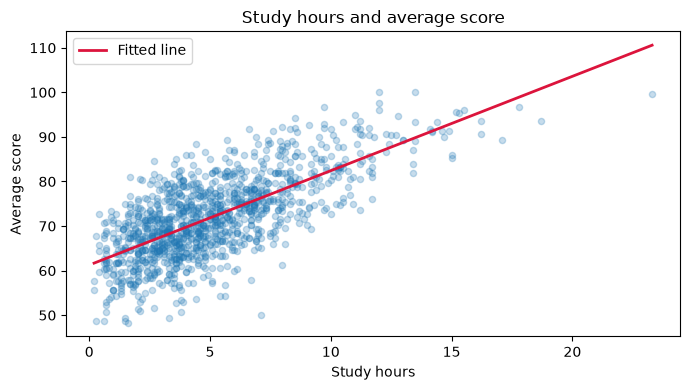

In [9]:
slope, intercept = np.polyfit(students["study_hours"], students["average_score"], deg=1)
predicted_scores = slope * students["study_hours"] + intercept
residual_sum_squares = ((students["average_score"] - predicted_scores) ** 2).sum()
total_sum_squares = ((students["average_score"] - students["average_score"].mean()) ** 2).sum()
r_squared = 1 - residual_sum_squares / total_sum_squares
print(f"Slope: {slope:.3f} average-score points per additional study hour")
print(f"Intercept: {intercept:.3f}")
print(f"R-squared: {r_squared:.3f}")

ax = students.plot(kind="scatter", x="study_hours", y="average_score", alpha=0.25,
                   figsize=(7, 4), title="Study hours and average score")
x_line = np.linspace(students["study_hours"].min(), students["study_hours"].max(), 100)
ax.plot(x_line, slope * x_line + intercept, color="crimson", linewidth=2, label="Fitted line")
ax.set_xlabel("Study hours")
ax.set_ylabel("Average score")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "study_hours_trend.png", dpi=150, bbox_inches="tight")
plt.show()

Each additional study hour is associated with an estimated **2.117-point increase** in average score in this fitted line (R² = **0.495**). The line accounts for 49.5% of the sample variation in average scores. One limitation is that this is a synthetic, one-variable association that omits other factors and is not validated for predicting individual learners.

## Findings

1. **99 learners (8.2%) are At Risk**, while 672 (56.0%) are Meeting and 429 (35.8%) are Exceeding; the sample mean is 72.01.
2. **Nairobi has the highest At Risk share at 9.2% (17/184)**; Mombasa has the most At Risk learners by count (19/212), so rate and caseload point to different priorities.
3. **Private-school learners average 76.01 versus 70.46 in public schools**, a 5.55-point gap. The descriptive gap stays positive within every attendance band (4.88-6.58 points) and study-hour quartile (3.59-7.80 points); this does not establish a school-type effect.
4. **Study hours are positively associated with scores** (r = 0.704); the fitted slope is 2.117 points per hour with R² = 0.495. The three strongest correlations with the average are English (0.827), science (0.815) and math (0.814), partly by construction because they define the average.
5. **Study hours are right-skewed** (median 4.5, mean 5.08); 29 learners (2.4%) exceed the 1.5 x IQR upper fence of 12.4 hours. The gender mean difference is small (72.10 for F vs 71.91 for M).

## Recommendations

1. Start support with individual learners below 60, then monitor county caseloads. Nairobi has the highest risk share and Mombasa the largest At Risk count in this sample; confirm these priorities with real, current school records before allocating funds.
2. Pilot structured study support and subject tutoring, especially for learners below 60 and in the lower study-hour quartiles. Evaluate outcomes against a comparison group before expanding; the observed study-hours relationship is not proof that extra hours alone improve scores.

## Limitations

The dataset is synthetic and cross-sectional, so patterns may not generalize to real learners and do not establish causal effects. Correlations of the subject scores with `average_score` are partly mechanical because those same scores define the average. The fitted study-hours line is univariate, omits relevant covariates and uncertainty, and should not be used to predict individual outcomes. Subgroup comparisons are descriptive and may reflect different group composition.